In [10]:
# %pip install numpy pandas scikit-learn tensorflow matplotlib

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Cố định seed để tái lập kết quả
np.random.seed(42)
tf.random.set_seed(42)

In [11]:
VOCAB_SIZE = 10000  # Giữ lại 10.000 từ phổ biến nhất
MAX_LEN = 200       # Độ dài chuỗi tối đa cho RNN/LSTM

print("Đang tải bộ dữ liệu IMDB...")
(X_train_seq, y_train), (X_test_seq, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print(f"Tổng số mẫu: {len(X_train_seq) + len(X_test_seq)}")
print(f"Tập Train: {len(X_train_seq)} mẫu (Pos: {np.sum(y_train==1)}, Neg: {np.sum(y_train==0)})")
print(f"Tập Test : {len(X_test_seq)} mẫu (Pos: {np.sum(y_test==1)}, Neg: {np.sum(y_test==0)})")

Đang tải bộ dữ liệu IMDB...
Tổng số mẫu: 50000
Tập Train: 25000 mẫu (Pos: 12500, Neg: 12500)
Tập Test : 25000 mẫu (Pos: 12500, Neg: 12500)


In [12]:
results = []

def evaluate_model(name, y_true, y_pred, train_time):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "Train Time (s)": round(train_time, 2)
    })
    print(f"\n--- Kết quả {name} ---")
    print(f"Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Time: {train_time:.2f}s")

In [13]:
# Chuyển chuỗi chỉ số từ sang chuỗi văn bản
X_train_text = [" ".join(map(str, seq)) for seq in X_train_seq]
X_test_text = [" ".join(map(str, seq)) for seq in X_test_seq]

print("Đang trích xuất đặc trưng TF-IDF cho SVM và Logistic Regression...")
tfidf = TfidfVectorizer(max_features=VOCAB_SIZE, token_pattern=r"(?u)\b\w+\b")
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)
print("Hoàn tất TF-IDF!")

Đang trích xuất đặc trưng TF-IDF cho SVM và Logistic Regression...
Hoàn tất TF-IDF!


In [14]:
start_time = time.time()
lr_model = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
lr_model.fit(X_train_tfidf, y_train)
lr_time = time.time() - start_time

y_pred_lr = lr_model.predict(X_test_tfidf)
evaluate_model("Logistic Regression", y_test, y_pred_lr, lr_time)


--- Kết quả Logistic Regression ---
Accuracy: 0.8862 | F1-Score: 0.8868 | Time: 0.61s


In [15]:
start_time = time.time()
svm_model = LinearSVC(C=1.0, random_state=42)
svm_model.fit(X_train_tfidf, y_train)
svm_time = time.time() - start_time

y_pred_svm = svm_model.predict(X_test_tfidf)
evaluate_model("SVM (LinearSVC)", y_test, y_pred_svm, svm_time)


--- Kết quả SVM (LinearSVC) ---
Accuracy: 0.8760 | F1-Score: 0.8754 | Time: 1.21s


In [16]:
# Padding chuỗi về cùng độ dài MAX_LEN
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='pre', truncating='pre')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='pre', truncating='pre')

EMBEDDING_DIM = 128
BATCH_SIZE = 128
EPOCHS = 5

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
print(f"Kích thước X_train_pad: {X_train_pad.shape}")

Kích thước X_train_pad: (25000, 200)


In [17]:
print("Đang huấn luyện mô hình Simple RNN...")
rnn_model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    SimpleRNN(64, dropout=0.2),
    Dense(1, activation='sigmoid')
])
rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_rnn = rnn_model.fit(
    X_train_pad, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)
rnn_time = time.time() - start_time

y_pred_rnn = (rnn_model.predict(X_test_pad) >= 0.5).astype(int).flatten()
evaluate_model("Simple RNN", y_test, y_pred_rnn, rnn_time)

Đang huấn luyện mô hình Simple RNN...
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


157/157 ━━━━━━━━━━━━━━━━━━━━ 15s 89ms/step - accuracy: 0.7291 - loss: 0.5167 - val_accuracy: 0.8524 - val_loss: 0.3600
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 84ms/step - accuracy: 0.8507 - loss: 0.3485 - val_accuracy: 0.8034 - val_loss: 0.4344
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 87ms/step - accuracy: 0.9063 - loss: 0.2366 - val_accuracy: 0.8604 - val_loss: 0.3767
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step

--- Kết quả Simple RNN ---
Accuracy: 0.8442 | F1-Score: 0.8519 | Time: 56.33s


In [18]:
print("Đang huấn luyện mô hình LSTM...")
lstm_model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    LSTM(64, dropout=0.2),
    Dense(1, activation='sigmoid')
])
lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_lstm = lstm_model.fit(
    X_train_pad, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)
lstm_time = time.time() - start_time

y_pred_lstm = (lstm_model.predict(X_test_pad) >= 0.5).astype(int).flatten()
evaluate_model("LSTM", y_test, y_pred_lstm, lstm_time)

Đang huấn luyện mô hình LSTM...
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


157/157 ━━━━━━━━━━━━━━━━━━━━ 43s 267ms/step - accuracy: 0.7843 - loss: 0.4408 - val_accuracy: 0.8620 - val_loss: 0.3306
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 43s 274ms/step - accuracy: 0.8984 - loss: 0.2513 - val_accuracy: 0.8644 - val_loss: 0.3167
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 41s 259ms/step - accuracy: 0.9147 - loss: 0.2171 - val_accuracy: 0.8388 - val_loss: 0.3637
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 256ms/step - accuracy: 0.9288 - loss: 0.1837 - val_accuracy: 0.8268 - val_loss: 0.3974
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step

--- Kết quả LSTM ---
Accuracy: 0.8656 | F1-Score: 0.8699 | Time: 167.25s



================ BẢNG SO SÁNH KẾT QUẢ ================


,Model,Accuracy,Precision,Recall,F1-Score,Train Time (s)
0,Logistic Regression,0.88620,0.882013,0.89168,0.886820,0.61
1,SVM (LinearSVC),0.87596,0.879328,0.87152,0.875407,1.21
2,Simple RNN,0.84416,0.811649,0.89632,0.851886,56.33
3,LSTM,0.86560,0.842733,0.89896,0.869939,167.25


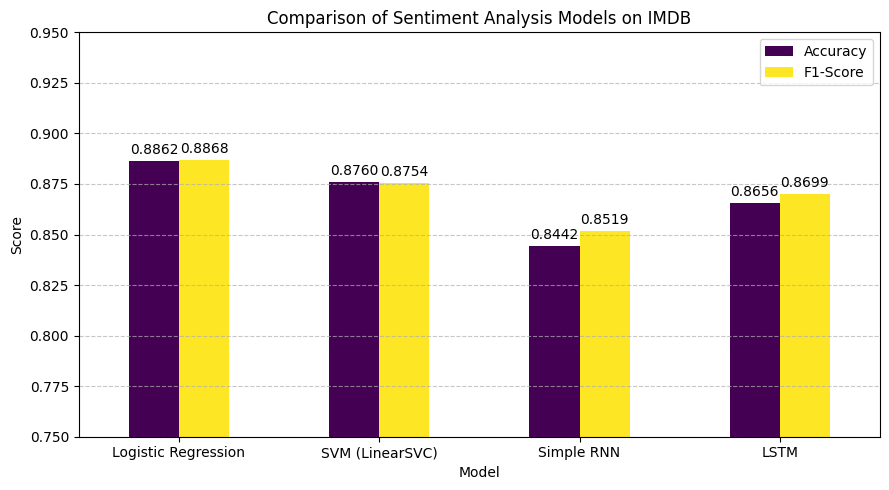

In [19]:
df_results = pd.DataFrame(results)
print("\n================ BẢNG SO SÁNH KẾT QUẢ ================")
display(df_results) # Dùng display thay vì print để bảng hiển thị đẹp hơn trong Jupyter

# Vẽ biểu đồ so sánh Accuracy và F1-Score
ax = df_results.plot(
    x="Model", y=["Accuracy", "F1-Score"], kind="bar",
    figsize=(9, 5), rot=0, ylim=(0.75, 0.95), colormap="viridis"
)
plt.title("Comparison of Sentiment Analysis Models on IMDB")
plt.ylabel("Score")
plt.grid(axis='y', linestyle='--', alpha=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3)
plt.tight_layout()
plt.show()